In [49]:
import numpy as np

# исходная функция, которую нужно аппроксимировать моделью a(x)
def func(x):
    return 0.5 * x + 0.2 * x ** 2 - 0.05 * x ** 3 + 0.2 * np.sin(4 * x) - 2.5


# здесь объявляйте необходимые функции
def a(x, w):
    return w[0] + w[1]*x + w[2]*x**2 + w[3]*x**3

def Qk_fun(x, y, w):
    model = a(x, w)
    return np.mean((model - y)**2)

coord_x = np.arange(-4.0, 6.0, 0.1) # значения по оси абсцисс [-4; 6] с шагом 0.1
coord_y = func(coord_x) # значения функции по оси ординат

sz = len(coord_x)	# количество значений функций (точек)
eta = np.array([0.1, 0.01, 0.001, 0.0001]) # шаг обучения для каждого параметра w0, w1, w2, w3
w = np.array([0., 0., 0., 0.]) # начальные значения параметров модели
N = 500 # число итераций алгоритма SGD
lm = 0.02 # значение параметра лямбда для вычисления скользящего экспоненциального среднего
batch_size = 50 # размер мини-батча (величина K = 50)

Qe = np.mean((a(coord_x, w) - coord_y)**2) # начальное значение среднего эмпирического риска
np.random.seed(0) # генерация одинаковых последовательностей псевдослучайных чисел

for i in range(N):
    k = np.random.randint(0, sz-batch_size) # sz - размер выборки (массива coord_x)
    
    error_batch = a(coord_x[k:k+batch_size], w) - coord_y[k:k+batch_size]
    
    stohastic_gradien = np.array([
        np.mean(2*error_batch), 
        np.mean(2*error_batch * coord_x[k:k+batch_size]),
        np.mean(2*error_batch * coord_x[k:k+batch_size]**2),
        np.mean(2*error_batch * coord_x[k:k+batch_size]**3)
    ])
    
    
    w = w - eta * stohastic_gradien
    
    Qk = Qk_fun(coord_x, coord_y, w)
    
    Qe = lm*Qk + (1-lm)*Qe
    
    
    
    
Q = np.mean((a(coord_x, w) - coord_y)**2)
    
    
    

In [50]:
print(Qe)
print(Q)

0.020741500000468167
0.02010989021755195


In [51]:
print(w)

[-2.49725214  0.49451654  0.19757031 -0.04967255]


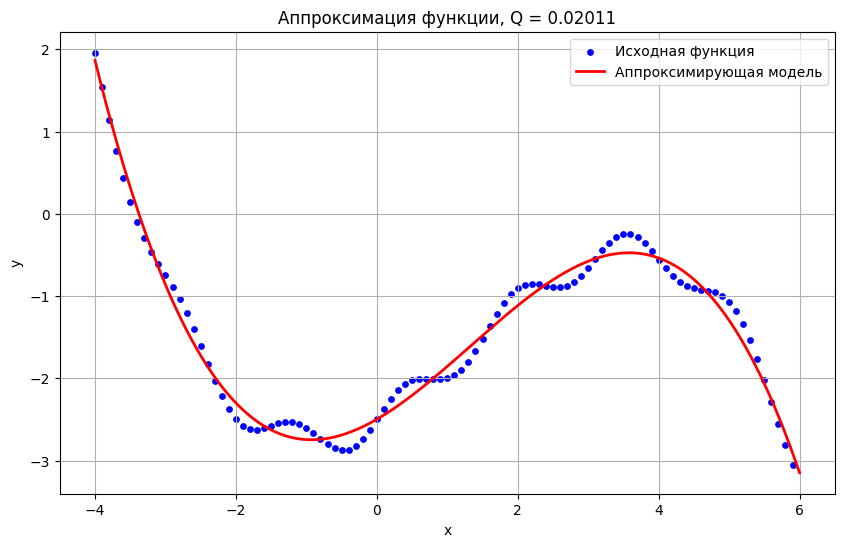

In [52]:
import matplotlib.pyplot as plt

x_plot = np.linspace(-4, 6, 1000)

plt.figure(figsize=(10, 6))

plt.scatter(
    coord_x,
    coord_y,
    color='blue',
    s=15,
    label='Исходная функция'
)

plt.plot(
    x_plot,
    a(x_plot, w),
    color='red',
    linewidth=2,
    label='Аппроксимирующая модель'
)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Аппроксимация функции, Q = {Q:.5f}')
plt.grid()
plt.legend()
plt.show()